###############################################################################
#           Aydin Loid Karatas
#           ---
#           University of Southern California
#           Department of Quantitative and Computational Biology
#           Mooney Lab
#           ---
#           draw_3T.py
###############################################################################

In [46]:
import pickle
import demesdraw
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from matplotlib.patches import FancyArrowPatch

In [43]:
# plotting preparation
demo_pkl = "/scratch1/karatas/msprime_runs_chr18_admix_3T/trees/HapMapII_GRCh38_1_all.demography.pkl"

with open(demo_pkl, "rb") as file:
    demo = pickle.load(file)

demo_graph = demo.to_demes()

# define population positions in drawn graph
AFR_loc = 0
EUR_loc = 1_050_000
ADMIX_loc = 510_000
positions = {
    "AFR": AFR_loc,

    "ADMIX_G1": ADMIX_loc,
    "ADMIX_G2": ADMIX_loc,
    "ADMIX_G3": ADMIX_loc,
    "ADMIX_G4": ADMIX_loc,

    "ADMIX": ADMIX_loc,

    "ADMIX_G5": ADMIX_loc,
    "ADMIX_G6": ADMIX_loc,
    "ADMIX_G7": ADMIX_loc,
    "ADMIX_G8": ADMIX_loc,
    "ADMIX_G9": ADMIX_loc,

    "EUR": EUR_loc,
}

# pop colors
colors = {
    "AFR": "#56B4E9",
    "EUR": "#fb8072",
}

# lavender/purple gradient from light -> dark
admix_gradient = [
    "#E6D9FF",
    "#D6C2FF",
    "#C4A6FF",
    "#B38BFF",
    "#A06FFF",
    "#8D5AF5",
    "#7C49EC",
    "#703BE7",
    "#5E2FD1",
]
for i in range(1, 10):
    colors[f"ADMIX_G{i}"] = admix_gradient[i - 1]
colors["ADMIX"] = "#4B1FA8"

# remove AFR <-> EUR migrataion lines for visualization
filtered_migrations = []
for mig in demo_graph.migrations:
    pair = {mig.source, mig.dest}
    if pair == {"AFR", "EUR"}:
        continue
    filtered_migrations.append(mig)
demo_graph.migrations = filtered_migrations

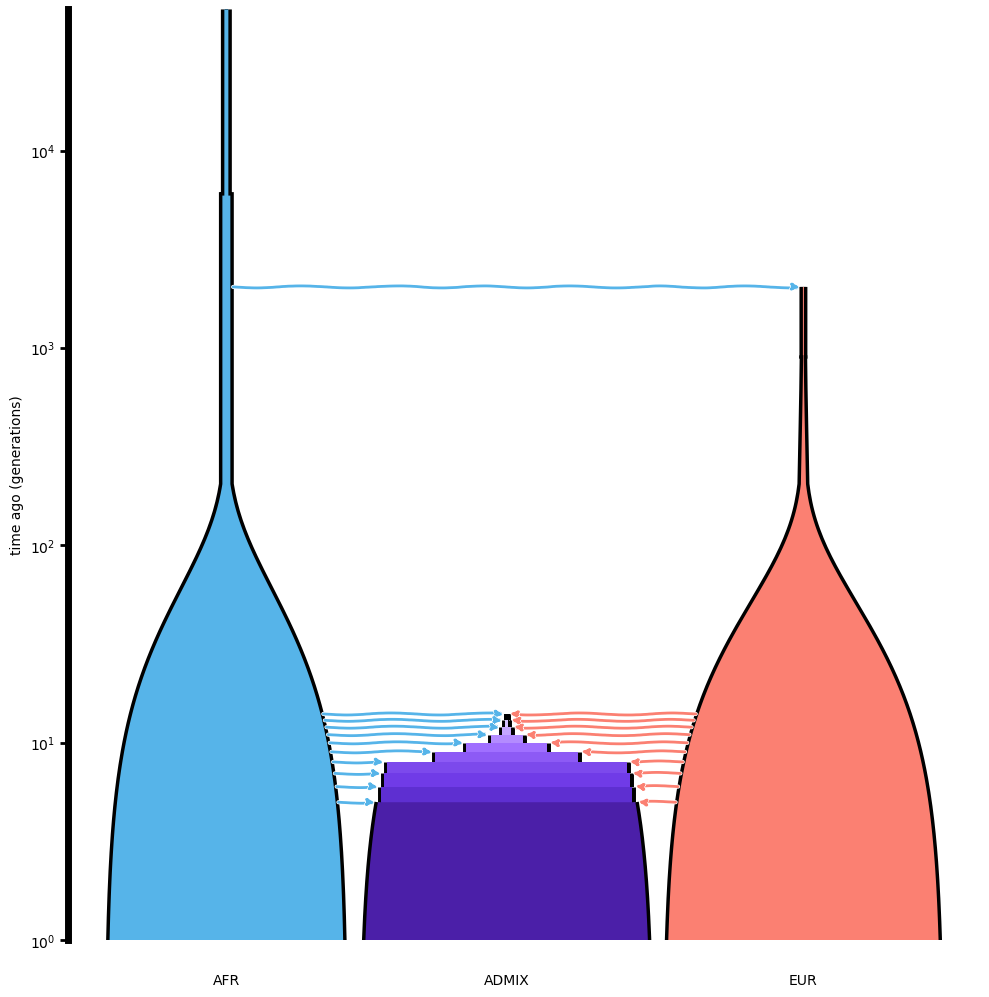

In [63]:
# plotting
plt.rcParams["svg.fonttype"] = "none"
fig, ax = plt.subplots(figsize=(10, 10))

demesdraw.tubes(
    demo_graph,
    ax=ax,
    positions=positions,
    colours=colors,
    log_time=True,
    labels=None
)

# add tube outlines
# outline only the population tubes
for patch in ax.patches:
    if isinstance(patch, FancyArrowPatch):
        # migration arrows: no outline
        patch.set_linewidth(2.0)
    else:
        # deme tubes: outlined
        patch.set_edgecolor("black")
        patch.set_linewidth(5.0)

# thicker axes
for spine in ax.spines.values():
    spine.set_linewidth(5.0)

ax.tick_params(width=2, length=6)

ax.text(AFR_loc, 0.6, "AFR", ha="center")
ax.text(ADMIX_loc, 0.6, "ADMIX", ha="center")
ax.text(EUR_loc, 0.6, "EUR", ha="center")

for artist in ax.get_children():
    if hasattr(artist, "set_alpha"):
        artist.set_alpha(1.0)

plt.tight_layout()
plt.show()

In [60]:
# save figure
fig.savefig(
    "/project2/jazlynmo_738/karatas/ibd_compare_results/demography_plot.svg",
    format="svg",
    bbox_inches="tight",
    transparent=True,
    dpi=300
)